# Predicting Inorganic Fertilizer Adoption on Rwandan Farm Plots
## Notebook 1 — Data Preparation and Exploratory Data Analysis

**Data source:** National Institute of Statistics of Rwanda (NISR), *Seasonal Agricultural Survey (SAS) 2020*, accessed through the NISR National Data Archive under its public-use licence. The raw files are **not** included in this repository (see the README for how to obtain them).

**Prediction task:** binary classification. Given what is known about a farm plot, its farmer and the farming practices used on it in a given season, predict whether **inorganic (mineral) fertilizer was applied to that plot** (survey question 3.9).

This notebook does the following:
1. Loads the raw Stata files for seasons A and B.
2. Combines the fertilizer, agricultural-practice and crop-production modules into **one row per plot per season**.
3. Removes variables that would leak the answer.
4. Explores the target and the main predictors.
5. Saves a clean modelling table plus a farmer-grouped train/validation/test split, which notebooks 2 (traditional ML) and 3 (deep learning) will use.

### Setup
All paths are relative to the repository root. Place the unzipped NISR download so that the Stata files sit in `data/raw/Datasets/STATA/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "Datasets" / "STATA"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Chart styling: two fixed colours for the two classes, recessive axes and grid
CLR = {"No": "#2a78d6", "Yes": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
})
print("Raw data folder found:", RAW.exists())

Raw data folder found: True


### 1. Load the raw survey modules
The SAS is published as separate files ("modules") for each season. We use seasons **A** (Sept–Feb) and **B** (Mar–Jun). Season C is small (about 5,600 rows) and mostly covers marshland and irrigated plots, so it is left out to keep the population comparable.

`pyreadstat` also returns the **value labels** stored in the Stata file (e.g. code `1` → `"Yes"`), which we use to make categorical variables readable.

In [2]:
FILES = {
    "fert":     "rwa-sas-Season{s}_PartIII_Fertilizers_Pesticides.dta",
    "practice": "rwa-sas-Season{s}_PartIV_Agricultural practice.dta",
    "crops":    "rwa-sas-season{s}_Crop production.dta",
}

def load(module, season):
    df, meta = pyreadstat.read_dta(RAW / FILES[module].format(s=season))
    return df, meta

raw = {(m, s): load(m, s) for m in FILES for s in "AB"}
for (m, s), (df, _) in raw.items():
    print(f"Season {s} | {m:9s} | {len(df):>6,} rows | {df.shape[1]} columns")
print("\nTotal raw rows across these six files:", f"{sum(len(d) for d, _ in raw.values()):,}")

Season A | fert      | 21,023 rows | 42 columns
Season B | fert      | 18,936 rows | 42 columns
Season A | practice  | 16,830 rows | 47 columns
Season B | practice  | 16,398 rows | 48 columns
Season A | crops     | 41,313 rows | 66 columns
Season B | crops     | 35,773 rows | 66 columns

Total raw rows across these six files: 150,273


**Raw dataset size.** The assignment requires at least 20,000 raw rows. The Season A fertilizer module alone has 21,023 rows, and the six modules used here have about 150,000 rows together.

Each plot is identified by three columns that appear in every module:
- `Segment_ID`: the survey area (a sampled segment of land)
- `s1q6`: farmer number within the segment
- `s2q1`: plot number

A farmer is therefore `Segment_ID + s1q6`, and a plot is `Segment_ID + s1q6 + s2q1` within a season.

In [3]:
KEY = ["Segment_ID", "s1q6", "s2q1"]
for (m, s), (df, _) in raw.items():
    print(f"Season {s} | {m:9s} | rows={len(df):>6,} | unique plots={df[KEY].drop_duplicates().shape[0]:>6,}")

Season A | fert      | rows=21,023 | unique plots=16,830
Season B | fert      | rows=18,936 | unique plots=16,398
Season A | practice  | rows=16,830 | unique plots=16,830
Season B | practice  | rows=16,398 | unique plots=16,398
Season A | crops     | rows=41,313 | unique plots=16,830
Season B | crops     | rows=35,773 | unique plots=16,467


The fertilizer and crop-production files contain **more than one row per plot**: one row for each fertilizer type or crop recorded. Plot-level fields such as gender, age and plot area are identical across those repeated rows (this was checked during exploration), so we can safely reduce each module to one row per plot.

### 2. Build plot-level features from each module

#### 2a. Fertilizer & pesticide module → target and farmer/plot attributes
**Target:** `inorganic_fert = 1` if *any* row for the plot answers "Yes" to question 3.9.

**Columns deliberately excluded (data leakage):**

| Variable | Question | Why it is excluded |
|---|---|---|
| `s3q7` | Inorganic fertilizer used on *any* of the farmer's plots | If "No", the plot target is always "No". It almost encodes the answer. |
| `s3q8`, `s3q10`–`s3q15` | Source, type, unit, quantity, price, crop fertilized | Only answered *after* a "Yes", so they exist only for positive cases. |
| `s3q16`–`s3q17` | Micro-nutrient use | Usually bought and applied together with mineral fertilizer, so it acts as a proxy for the target. |
| `s3q18`–`s3q24` | Pesticide use, type, quantity, cost | Same input-purchasing decision as fertilizer, so it is a near-proxy. Kept separately so you can test it as an ablation if you want. |

Organic fertilizer (manure/compost, `s3q1`, `s3q3`) **is kept**. It is a different input, mostly produced on the farm, and how it relates to mineral fertilizer is a legitimate question for the analysis.

In [4]:
def labels(meta, col):
    return meta.variable_value_labels.get(col, {})

def fert_plot_table(season):
    df, meta = raw[("fert", season)]
    g = df.groupby(KEY)
    out = g.agg(
        province=("s1q1", "first"), district=("s1q2", "first"), stratum=("s1q3", "first"),
        farmer_type=("s1q7", "first"), gender=("s1q8", "first"), age=("s1q9", "first"),
        plot_area_m2=("s2q2", "first"), n_main_crops=("s2q3", "first"),
        organic_fert_any_plot=("s3q1", lambda x: int((x == 1).any())),
        organic_fert_plot=("s3q3", lambda x: int((x == 1).any())),
        pesticide_plot=("s3q19", lambda x: int((x == 1).any())),   # kept only for an optional ablation
        inorganic_fert=("s3q9", lambda x: int((x == 1).any())),     # TARGET
        plot_weight=("plot_weight", "first"),                      # survey weight, not a feature
    ).reset_index()
    for col, src in [("province", "s1q1"), ("district", "s1q2"), ("stratum", "s1q3"),
                     ("farmer_type", "s1q7"), ("gender", "s1q8")]:
        out[col] = out[col].map(labels(meta, src))
    for col in ["age", "plot_area_m2", "n_main_crops"]:   # some numeric columns are stored as text in Season B
        out[col] = pd.to_numeric(out[col], errors="coerce")
    out["season"] = season
    return out

fert = pd.concat([fert_plot_table(s) for s in "AB"], ignore_index=True)
print(fert.shape); fert.head()

(33228, 17)


,Segment_ID,s1q6,s2q1,province,district,stratum,farmer_type,gender,age,plot_area_m2,n_main_crops,organic_fert_any_plot,organic_fert_plot,pesticide_plot,inorganic_fert,plot_weight,season
0,12001,1,1,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,60.0,121702.742188,1,1,1,0,1,1.0,A
1,12001,1,2,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,60.0,167580.734375,1,1,1,1,1,1.0,A
2,12001,1,3,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,60.0,347529.406250,1,1,1,0,0,1.0,A
3,12001,1,4,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,60.0,7522.296875,1,1,1,0,0,1.0,A
4,12001,1,36,Kigali,Gasabo,LSF,Large scale farmer as individual,Male,60.0,17042.148438,1,0,0,0,0,1.0,A


#### 2b. Agricultural-practice module → land, erosion, mechanisation and irrigation features
This module already has exactly one row per plot. We keep practices that describe the plot and how it was worked: land consolidation, erosion severity, anti-erosion structures, oxen or tractor ploughing, other machinery, hired-labour spending, and irrigation.

Several questions have a "filter" structure. For example, `s4q13` (was *this plot* irrigated?) is only asked if `s4q12` (irrigation on *any* plot) was "Yes". A missing value in the follow-up question therefore means "No", not "unknown", and we encode it that way.

In [5]:
def yes(x):  # survey coding: 1 = Yes, 2 = No
    return (x == 1).astype(int)

def practice_plot_table(season):
    df, meta = raw[("practice", season)]
    out = df[KEY].copy()
    out["land_consolidation"] = yes(df["s3q25"])
    out["erosion_degree"] = df["s4q1"].map(labels(meta, "s4q1")).str.split(" ").str[0]  # Very / Low / Moderate / Severe
    out["erosion_degree"] = out["erosion_degree"].replace({"Very": "Very low"})
    out["anti_erosion_plot"] = yes(df["s4q3"])
    out["mechanical_any_plot"] = yes(df["s4q6"])
    out["oxen_plot"] = yes(df["s4q8_1"])
    out["tractor_plot"] = yes(df["s4q9_1"])
    out["other_machine_plot"] = yes(df["s4q10_1"])
    out["hired_labour_rwf"] = pd.to_numeric(df["s4q11"], errors="coerce")  # stored as text in Season B
    out["irrigated_plot"] = yes(df["s4q13"])
    out["season"] = season
    return out

practice = pd.concat([practice_plot_table(s) for s in "AB"], ignore_index=True)
print(practice.shape); practice.head()

(33228, 13)


,Segment_ID,s1q6,s2q1,land_consolidation,erosion_degree,anti_erosion_plot,mechanical_any_plot,oxen_plot,tractor_plot,other_machine_plot,hired_labour_rwf,irrigated_plot,season
0,12001,1,1,1,Very low,1,1,0,1,0,720000.0,0,A
1,12001,1,2,1,Very low,0,1,0,1,0,1200200.0,0,A
2,12001,1,3,0,Very low,0,1,0,1,0,5506800.0,0,A
3,12001,1,4,0,Very low,0,0,0,0,0,150000.0,0,A
4,12001,1,36,0,Very low,1,0,0,0,0,0.0,0,A


#### 2c. Crop-production module → what is grown on the plot and whether improved seed was used
One row per crop per plot. We turn this into:
- **Crop indicator columns** (one-hot encoding of the crop list), e.g. `crop_Maize = 1` if maize is grown on the plot. Fertilizer use in Rwanda is strongly tied to specific crops (maize, Irish potato, rice, wheat) promoted under the Crop Intensification Programme, so we expect these to be among the strongest predictors.
- `improved_seed_plot`: improved seed was sown for at least one crop on the plot (`s2q11` = improved, or both types).
- `n_crop_records`: number of crops recorded.

**Excluded:** all harvest, sales, storage and loss quantities (`s2q19` onward). These are *outcomes* of the season and are themselves affected by fertilizer use, so they would not be known when a prediction is made.

In [6]:
def crop_plot_table(season):
    df, meta = raw[("crops", season)]
    d = df[KEY].copy()
    d["crop"] = df["CropCategory"].map(labels(meta, "CropCategory"))
    d["improved"] = df["s2q11"].isin([2, 3]).astype(int)   # 2 = improved, 3 = both
    seed_lab = labels(meta, "s2q11")
    assert seed_lab.get(2, "").startswith("Improved"), seed_lab  # guard: check the coding before trusting it
    crops = pd.crosstab([d[k] for k in KEY], d["crop"]).clip(upper=1).add_prefix("crop_")
    crops.columns = crops.columns.str.replace(r"[^0-9A-Za-z_]+", "_", regex=True)
    agg = d.groupby(KEY).agg(improved_seed_plot=("improved", "max"), n_crop_records=("crop", "size"))
    out = agg.join(crops).reset_index()
    out["season"] = season
    return out

crops = pd.concat([crop_plot_table(s) for s in "AB"], ignore_index=True).fillna(0)
crop_cols = [c for c in crops.columns if c.startswith("crop_")]
print(crops.shape, "| crop indicator columns:", len(crop_cols))

(33297, 27) | crop indicator columns: 21


### 3. Merge into one modelling table (one row = one plot in one season)

In [7]:
MKEY = KEY + ["season"]
df = (fert.merge(practice, on=MKEY, how="left", validate="one_to_one")
          .merge(crops, on=MKEY, how="left", validate="one_to_one"))
df["farmer_id"] = df["Segment_ID"].astype(str) + "_" + df["s1q6"].astype(str)
df["plot_uid"] = df["farmer_id"] + "_" + df["s2q1"].astype(str) + "_" + df["season"]

print("Rows (plot-seasons):", f"{len(df):,}")
print("Distinct farmers:   ", f"{df.farmer_id.nunique():,}")
print("Plots with no crop-production record:", df["n_crop_records"].isna().sum())
df[crop_cols + ["improved_seed_plot", "n_crop_records"]] = df[crop_cols + ["improved_seed_plot", "n_crop_records"]].fillna(0)

Rows (plot-seasons): 33,228
Distinct farmers:    16,854
Plots with no crop-production record: 920


### 4. Data quality checks

In [8]:
miss = df.isna().mean().sort_values(ascending=False)
print("Share of missing values (columns with any missing):")
print((miss[miss > 0] * 100).round(2).astype(str) + " %")
print("\nPlot area (m²):"); print(df["plot_area_m2"].describe(percentiles=[.01, .25, .5, .75, .99]).round(0))
print("\nAge:"); print(df["age"].describe().round(1))

Share of missing values (columns with any missing):
age                 3.26 %
gender              3.25 %
farmer_type         0.55 %
hired_labour_rwf    0.01 %
erosion_degree       0.0 %
dtype: str

Plot area (m²):
count       33228.0
mean        15360.0
std        206272.0
min            28.0
1%            114.0
25%           548.0
50%          1074.0
75%          2184.0
99%        191666.0
max      10203921.0
Name: plot_area_m2, dtype: float64

Age:
count    32144.0
mean        48.6
std         14.7
min          6.0
25%         37.0
50%         47.0
75%         60.0
max        115.0
Name: age, dtype: float64


**Things to notice:**
- **Plot area is extremely right-skewed.** The median is about 1,100 m² (0.11 ha, typical for Rwandan smallholdings), but large-scale farms reach 1,000 ha. We add a `log_plot_area` feature, because linear models and neural networks handle a log scale much better.
- **Hired-labour spending** is also skewed and contains many zeros, so it gets `log1p`.
- **Age** ranges from 6 to 115. Values below about 15 or above 100 are probably entry errors; you will notice them in the histogram below. The age histogram is also spiky at 30, 40, 50 and 60. This is *age heaping*, which is common in surveys where respondents round their age. Neither problem is severe, but both are worth one sentence in your limitations section.
- Missing **gender/age** (~4–5%) mostly belong to large-scale farms run by cooperatives or companies, where there is no individual farmer. Imputation is done later, inside the modelling pipelines, so that no information from the test set is used.

In [9]:
df["log_plot_area"] = np.log(df["plot_area_m2"])
df["log_hired_labour"] = np.log1p(df["hired_labour_rwf"].fillna(0))
df["season_A"] = (df["season"] == "A").astype(int)

### 5. Exploratory analysis

#### 5a. Target distribution

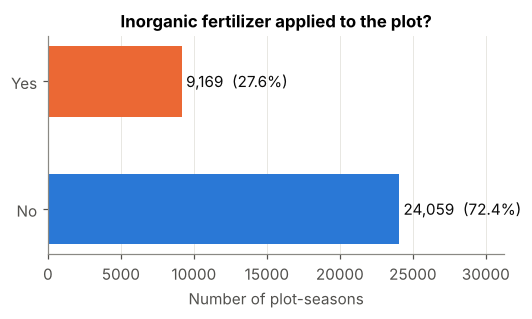

inorganic_fert      0      1
season                      
A               0.687  0.313
B               0.762  0.238


In [10]:
counts = df["inorganic_fert"].map({0: "No", 1: "Yes"}).value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.barh(counts.index, counts.values, color=[CLR["No"], CLR["Yes"]], height=0.55)
for b, v in zip(bars, counts.values):
    ax.text(v + 300, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / counts.sum():.1%})", va="center", color="#0b0b0b")
ax.set_xlabel("Number of plot-seasons"); ax.set_title("Inorganic fertilizer applied to the plot?")
ax.set_xlim(0, counts.max() * 1.3); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "01_target_distribution.png", bbox_inches="tight"); plt.show()
print(pd.crosstab(df["season"], df["inorganic_fert"], normalize="index").round(3))

> We have 27.6% Yes and 72.4% No this shows the Moderate imbalance “Yes” is clearly the minority, but it isn’t extreme. Extreme would be something like fraud detection, where only 1% are positive. We still have more than 9,000 “Yes” plots, plenty for the model to learn from.

#### 5b. Adoption rate by province and district

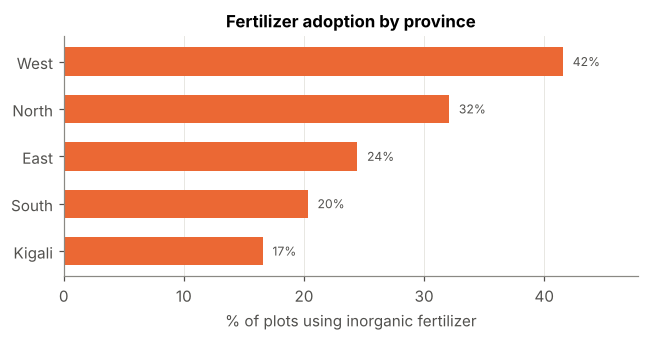

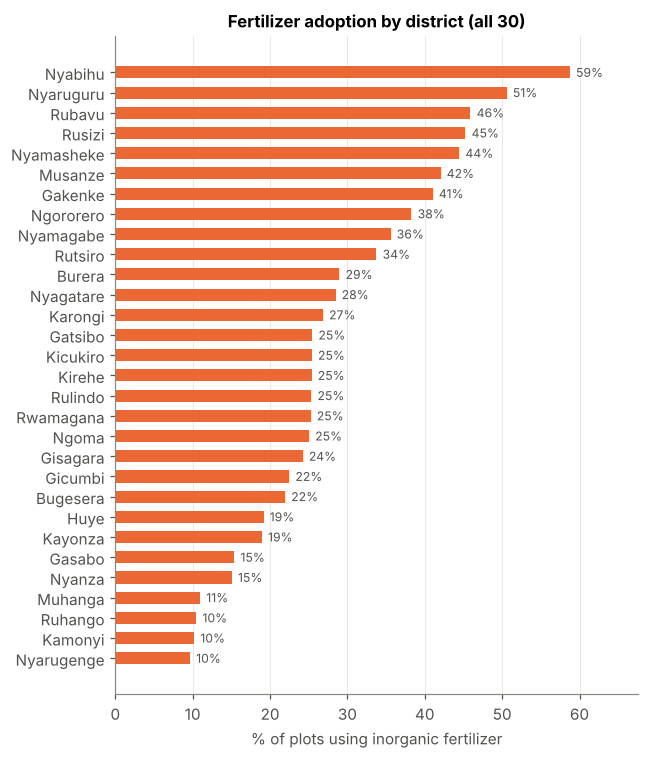

In [11]:
def rate_plot(col, title, fname, top=None, figsize=(6, 3.2)):
    r = df.groupby(col)["inorganic_fert"].agg(["mean", "size"]).sort_values("mean")
    if top: r = r.tail(top)
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(r.index.astype(str), r["mean"] * 100, color=CLR["Yes"], height=0.6)
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m * 100 + 0.8, i, f"{m:.0%}", va="center", fontsize=8, color="#52514e")
    ax.set_xlabel("% of plots using inorganic fertilizer"); ax.set_title(title)
    ax.set_xlim(0, r["mean"].max() * 100 * 1.15); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.savefig(FIG / fname, bbox_inches="tight"); plt.show()
    return r

rate_plot("province", "Fertilizer adoption by province", "02_by_province.png")
r_dist = rate_plot("district", "Fertilizer adoption by district (all 30)", "03_by_district.png", figsize=(6, 7))

here we can see that fertilizer adoption by province west comes first at 42% and kigali comes last at 17%  and basing on district nyabihu comes first at 59 aand nyarugenge at last wit adoption of 10% also in highlands areas seems to favor the plantation of Irish potatoe wuth Nyabihu, 36% of plots grow Irish potato. In Rubavu it’s 32%, and in Musanze 19%. These are volcanic highland districts in the North-West.

also the easter province surprisingly grows the most maize: 49% of its plots, and 66% in Nyagatare.
Yet its fertilizer rate is only 24%, close to average. So the idea that **maize intensification = high fertilizer use** is not clearly supported by this data. Eastern soils and flatter land may be naturally more fertile, so farmers feel less need for fertilizer.

#### 5c. Adoption rate by crop grown on the plot

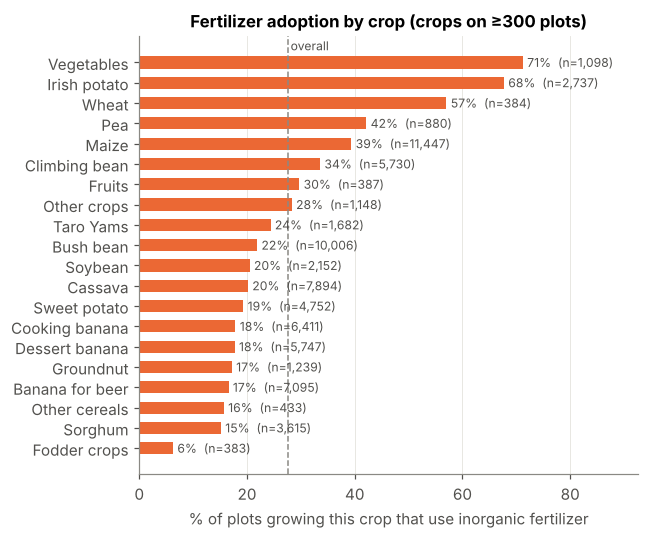

In [12]:
crop_rates = pd.DataFrame({
    c.replace("crop_", "").replace("_", " "): {
        "rate": df.loc[df[c] == 1, "inorganic_fert"].mean(), "n": int(df[c].sum())}
    for c in crop_cols}).T.query("n >= 300").sort_values("rate")
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(crop_rates.index, crop_rates["rate"] * 100, color=CLR["Yes"], height=0.6)
for i, (m, n) in enumerate(zip(crop_rates["rate"], crop_rates["n"])):
    ax.text(m * 100 + 0.8, i, f"{m:.0%}  (n={int(n):,})", va="center", fontsize=8, color="#52514e")
ax.axvline(df["inorganic_fert"].mean() * 100, color="#8a8984", lw=1, ls="--")
ax.text(df["inorganic_fert"].mean() * 100 + 0.5, len(crop_rates) - 0.4, "overall", fontsize=8, color="#52514e")
ax.set_xlabel("% of plots growing this crop that use inorganic fertilizer")
ax.set_title("Fertilizer adoption by crop (crops on ≥300 plots)")
ax.set_xlim(0, crop_rates["rate"].max() * 100 * 1.3); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "04_by_crop.png", bbox_inches="tight"); plt.show()

the most fertilized product is Vegetables  followed by Irish potatoes which is somehow correct because that a common food available on Rwanda Market it also shows that Fodder crops are not likely to be fertilized at only 6% which is also true because farms in Rwanda relies on just common glass to feed their cattle

#### 5d. Farm practices and plot characteristics

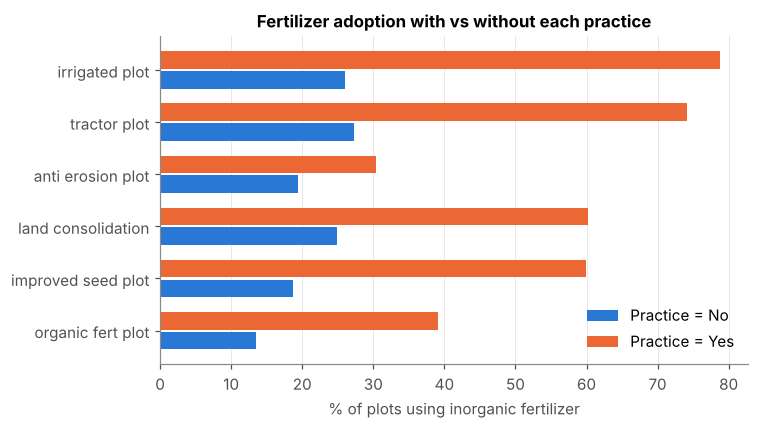

value                  No    Yes
feature                         
anti_erosion_plot    8440  24788
improved_seed_plot  26055   7173
irrigated_plot      32224   1004
land_consolidation  30681   2547
organic_fert_plot   14976  18252
tractor_plot        33054    174


In [13]:
binary = ["organic_fert_plot", "improved_seed_plot", "land_consolidation", "anti_erosion_plot",
          "tractor_plot", "irrigated_plot"]
rows = []
for c in binary:
    for v in (0, 1):
        sub = df.loc[df[c] == v, "inorganic_fert"]
        rows.append({"feature": c, "value": "Yes" if v else "No", "rate": sub.mean(), "n": len(sub)})
prac = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(binary)); h = 0.38
for k, v in enumerate(["No", "Yes"]):
    s = prac[prac.value == v].set_index("feature").loc[binary]
    ax.barh(y + (k - 0.5) * h, s["rate"] * 100, height=h - 0.04, color=CLR[v], label=f"Practice = {v}")
ax.set_yticks(y, [b.replace("_", " ") for b in binary])
ax.set_xlabel("% of plots using inorganic fertilizer"); ax.set_title("Fertilizer adoption with vs without each practice")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "05_by_practice.png", bbox_inches="tight"); plt.show()
print(prac.pivot(index="feature", columns="value", values="n"))

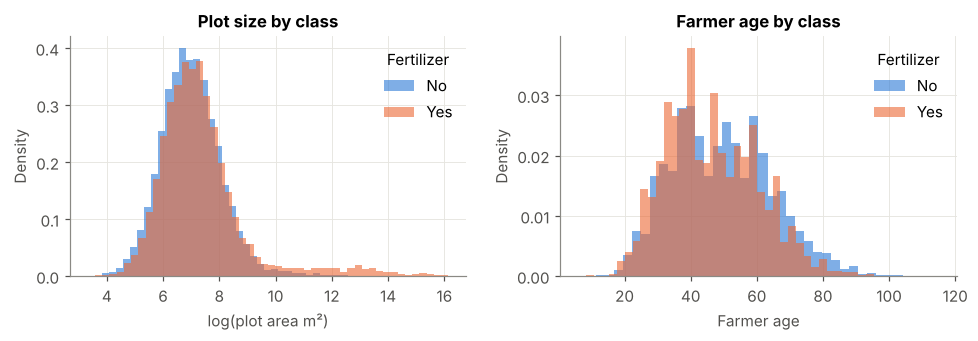

inorganic_fert      0      1
gender                      
Female          0.765  0.235
Male            0.714  0.286
inorganic_fert                                          0      1
farmer_type                                                     
Large scale  farmer as Coperative/Company/Assoc...  0.319  0.681
Large scale farmer as individual                    0.746  0.254
Small Scale farmer as Coperative/Company/Associ...  0.590  0.410
Small scale farmer as individual                    0.734  0.266


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for k, v in enumerate([0, 1]):
    lab = "Yes" if v else "No"
    axes[0].hist(df.loc[df.inorganic_fert == v, "log_plot_area"], bins=50, alpha=0.6, density=True, color=CLR[lab], label=lab)
    axes[1].hist(df.loc[df.inorganic_fert == v, "age"].dropna(), bins=40, alpha=0.6, density=True, color=CLR[lab], label=lab)
axes[0].set_xlabel("log(plot area m²)"); axes[0].set_title("Plot size by class")
axes[1].set_xlabel("Farmer age"); axes[1].set_title("Farmer age by class")
for a in axes: a.legend(title="Fertilizer", frameon=False); a.set_ylabel("Density")
plt.tight_layout(); plt.savefig(FIG / "06_area_age.png", bbox_inches="tight"); plt.show()
print(pd.crosstab(df["gender"], df["inorganic_fert"], normalize="index").round(3))
print(pd.crosstab(df["farmer_type"], df["inorganic_fert"], normalize="index").round(3))

The plot size histogram shows that plot size mostly doesn’t matter , except for very large plots use fertilizer more. also The age histogram shows that fertilizer users are slightly younger farmers,  with adoption falling from about 31% for under-40s to 21% for over-60s. Male farmers use fertilizer about 5 points, than female farmers (28.6% vs 23.5%), which may be because of unequal access to money, credit or training, not willingness. .

### 6. Final feature set

In [15]:
CATEGORICAL = ["province", "district", "stratum", "farmer_type", "gender", "erosion_degree"]
NUMERIC = ["age", "log_plot_area", "n_main_crops", "n_crop_records", "log_hired_labour"]
BINARY = ["season_A", "organic_fert_any_plot", "organic_fert_plot", "improved_seed_plot",
          "land_consolidation", "anti_erosion_plot", "mechanical_any_plot",
          "tractor_plot", "other_machine_plot", "irrigated_plot"] + crop_cols
TARGET = "inorganic_fert"
# oxen_plot is dropped: only 3 of 33,228 plots used oxen, so it carries no usable signal
ID_COLS = ["plot_uid", "farmer_id", "season", "plot_weight"]
OPTIONAL_ABLATION = ["pesticide_plot"]   # excluded from the main models, see Section 2a

model_df = df[ID_COLS + CATEGORICAL + NUMERIC + BINARY + OPTIONAL_ABLATION + [TARGET]].copy()
print(f"{len(CATEGORICAL)} categorical, {len(NUMERIC)} numeric, {len(BINARY)} binary features")
print("Modelling table:", model_df.shape)

6 categorical, 5 numeric, 31 binary features
Modelling table: (33228, 48)


### 7. Train / validation / test split, grouped by farmer
About **11,000 farmers appear in both seasons**, and most farmers have several plots. Plots from the same farmer share the same district, age, gender and farming habits. If they were split at random, the model could "recognise" a farmer it saw in training and score better than it would on genuinely new farmers.

We therefore use `GroupShuffleSplit` with `farmer_id` as the group, so **every farmer appears in exactly one split** (70% train / 15% validation / 15% test). Both notebook 2 and notebook 3 will use these exact split labels so that the traditional ML and deep learning models are compared on the same test plots.

In [16]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_idx, tmp_idx = next(gss.split(model_df, groups=model_df["farmer_id"]))
tmp = model_df.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_rel, te_rel = next(gss2.split(tmp, groups=tmp["farmer_id"]))

model_df["split"] = "train"
model_df.iloc[tmp_idx[va_rel], model_df.columns.get_loc("split")] = "val"
model_df.iloc[tmp_idx[te_rel], model_df.columns.get_loc("split")] = "test"

summary = model_df.groupby("split").agg(plots=("plot_uid", "size"), farmers=("farmer_id", "nunique"),
                                        fert_rate=(TARGET, "mean")).loc[["train", "val", "test"]]
print(summary.round(3))
overlap = set(model_df.query("split=='train'").farmer_id) & set(model_df.query("split=='test'").farmer_id)
print("Farmers in both train and test:", len(overlap))

       plots  farmers  fert_rate
split                           
train  23127    11797      0.277
val     5056     2528      0.272
test    5045     2529      0.277
Farmers in both train and test: 0


### 8. Save outputs
The processed table goes to `data/processed/`. That folder is listed in `.gitignore`, because it is derived from licensed microdata and must not be pushed to GitHub. The feature lists are saved as JSON so the modelling notebooks use exactly the same columns.

In [17]:
import json
model_df.to_parquet(OUT / "plots_model_table.parquet", index=False)
json.dump({"categorical": CATEGORICAL, "numeric": NUMERIC, "binary": BINARY, "target": TARGET,
           "optional_ablation": OPTIONAL_ABLATION, "id_cols": ID_COLS},
          open(OUT / "feature_spec.json", "w"), indent=2)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  feature_spec.json
  plots_model_table.parquet


### Summary and next steps
The final modelling dataset contain 33,228 plot-seasons (one row = one plot in one season) from 16,854 farmers
covering all 30 districts, seasons A and B of 2020. built from 150,273 raw rows in 6 survey files
43 features: 6 categorical (like district), 5 numeric (like age), 32 yes/no (like crops grown)
target: 27.6% used fertilizer, 72.4% did not, so the data is moderately imbalanced.

The exploratory analysis revealed that fertilizer use varies a lot by place: West 42% vs Kigali 17%; Nyabihu 59% vs Nyarugenge 10%
Season A has more fertilizer use (31%) than Season B (24%) farmers who use improved seed use fertilizer much more (60% vs 19%) organic manure is used together with mineral fertilizer, not instead of it (78% of fertilizer users also use manure) cooperatives use far more fertilizer (68%) than individual farmers (about 26%)

The strongest pattern was the crop grown on the plot high: vegetables 71%, Irish potato 68%, wheat 57% low: cassava 20%, sorghum 15%, fodder 6% reason: high-value, market-oriented crops get fertilizer; subsistence crops don’t

To prevent data leakage, I removed the question “did you use fertilizer on any of your plots”, which almost gives the answer fertilizer type, quantity, price and source, which only exist if the answer is Yes micronutrient and pesticide use, which are bought together with fertilizer (near-proxies) all harvest and sales amounts, which happen after fertilizer is applied.

Because many farmers manage several plots, I split the data by farmer so that no farmer appears in both training and testing (checked: 0 overlap) the model can’t “recognise” a farmer’s habits from training, which would inflate the scores about 11,000 farmers appear in both seasons, so this matters a lot here split: 70% train (23,127 plots), 15% validation (5,056), 15% test (5,045) all three parts have almost the same fertilizer rate (27–28%), so they’re fair samples

**Next:** `02_traditional_ml.ipynb`, with scikit-learn pipelines (one-hot encoding plus scaling), Logistic Regression, Random Forest, Gradient Boosting and SVM, and hyperparameter tuning with `GroupKFold`.